# Tuning plots, several units → `tuning_plots.pdf`

The **tuning column** of [`../figure_2/psth.ipynb`](../figure_2/psth.ipynb), for several
units side by side: one column per unit, in `UNITS` order, with the same three ring rows as
the PSTH figure plus a row of line plots underneath.

| row | conditions | drawn as |
|---|---|---|
| 1 object | one object anywhere on the ring | a shaded annulus |
| 90° apart | two objects 90° apart, all orientations | a dense family of chords |
| 180° apart | the antipodal pairs | the same, over half a turn |
| lines | one curve per angle in `LINE_SEPS_DEG` | firing rate vs. direction |

All the tuning logic — trial binning, firing rates, prototype sets, colour scales, ring
drawers — comes from figure 2's `psth_lib`, so these panels are the *same objects* as that
figure's tuning column. `tuning_lib` only lays them out in a grid.

Colour is each condition's mean firing rate over the stimulus and delay phases. A unit's two
2-object rows share one colour scale so they can be compared with each other; the 1-object
row is always on its own (its rates are not comparable to the 2-object ones), and no scale
is ever shared *across* units — which is why the colourbar is a key for the blue→red
direction only, with no numbers on it.

Each unit's `orientation_deg` sets the phase of its prototype set **and** rotates its rings
by the same angle, so it is the knob for turning a unit until its receptive field lines up
with the others. Only the drawing moves: the conditions, their firing rates and their colour
scales are untouched.

**Ring size is set by `RING_SIZE_IN`, not by `FIGSIZE`.** Constrained layout divides up each
row's *decorated* height, so the line row's labels and the legend would otherwise eat into
the rings; `tuning_lib` instead resizes the whole figure until the ring panels are the
requested size.

In [7]:
import matplotlib.pyplot as plt

import common
import tuning_lib

common.set_style()

# (subject, session, unit, orientation_deg) — left-to-right column order. The angle rotates
# that unit's rings counter-clockwise, and sets the phase of its prototype set.
UNITS = [
    # ('Perle', '2022-06-16', 107, -135),
    # ('Perle', '2022-06-11', 166, -50),
    ('Perle', '2022-06-11', 188, -30),
    ('Perle', '2022-06-19', 186, -124),
    ('Perle', '2022-06-10', 158, 170),
    ('Perle', '2022-06-11', 143, -90),
    # ('Perle', '2022-06-11', 126, -87),
]

LINE_SEPS_DEG = [90, 120, 150, 180]   # inter-object angles in the line row, in legend order
# Per-unit y axis of the line panels, so a column gets round numbers instead of whatever its
# curves happen to span. figure_tuning.ipynb reads these, so a unit pinned here is pinned in
# both figures.
LINE_YLIM = {143: (5, 14)}
LINE_YTICKS = {143: (5, 10)}

# ── The two smoothings, in the order they are applied ────────────────────────────
# 1. Binning. A trial joins a prototype when BOTH of its objects are within this of their
#    own slot — ../figure_2/psth.ipynb's value, and the same binning code. It sets the
#    angular resolution of every panel, the ring rows and the line row alike: for a pair the
#    criterion is |Δmean| + |Δseparation|/2 ≤ window, a top-hat of this half-width along the
#    line row's x axis, so it alone gives the curves a FWHM of twice it. Smaller is sharper
#    and noisier — at 15° each sample averages ~20 trials, at 30° ~80.
SIMILARITY_WINDOW_DEG = 15.0

# 2. Cosmetic. A circular Gaussian applied to the already-binned curve at draw time; sigma
#    in degrees, 0 to switch it off. Unlike the window above it adds no trials, so it can
#    only hide sampling noise, never recover resolution. At the 15° window the two are
#    comparable (30° FWHM from the binning, 24° from a sigma of 10) and the combined
#    resolution is ~33°; at a 30° window this was decorative.
#
#    LINE_SMOOTH_DEG_1OBJ does double duty: the 1-object curve is not drawn here
#    (`line_1obj` is False), but it is still what x = 0 is found on — the peak of the
#    smoothed 1-object curve is each column's receptive-field centre. Changing it shifts the
#    line panels horizontally without changing their shape.
LINE_SMOOTH_DEG_2OBJ = 20.0
LINE_SMOOTH_DEG_1OBJ = 30.0
# ────────────────────────────────────────────────────────────────────────────────

FIGSIZE = (6.0, 3.5)     # the STARTING size; the figure grows until the rings are ...
RING_SIZE_IN = 1.0       # ... this many inches square

## Build the panels

One set of ring rows and one set of line curves per unit, both from figure 2’s binning.

In [8]:
rows_per_unit = [tuning_lib.unit_rows(s, ses, u, orientation_deg=deg,
                                     similarity_window_deg=SIMILARITY_WINDOW_DEG)
                 for s, ses, u, deg in UNITS]
curves_per_unit = [tuning_lib.unit_curves(s, ses, u, LINE_SEPS_DEG, orientation_deg=deg,
                                          similarity_window_deg=SIMILARITY_WINDOW_DEG)
                   for s, ses, u, deg in UNITS]
print(f'{len(UNITS)} units, {len(LINE_SEPS_DEG)} inter-object angles each, '
      f'pooled within {SIMILARITY_WINDOW_DEG:g}°')

Perle 2022-06-11: 932 2-obj + 192 1-obj trials | unit 188 @ s0/good (1170 trials with spikes) | prototypes at -30°
Perle 2022-06-19: 1153 2-obj + 461 1-obj trials | unit 186 @ s0/good (1645 trials with spikes) | prototypes at -124°
Perle 2022-06-10: 962 2-obj + 198 1-obj trials | unit 158 @ s0/good (1206 trials with spikes) | prototypes at 170°
Perle 2022-06-11: 932 2-obj + 192 1-obj trials | unit 143 @ s0/good (1170 trials with spikes) | prototypes at -90°
4 units, 4 inter-object angles each, pooled within 15°


## The figure

saved tuning_plots.pdf


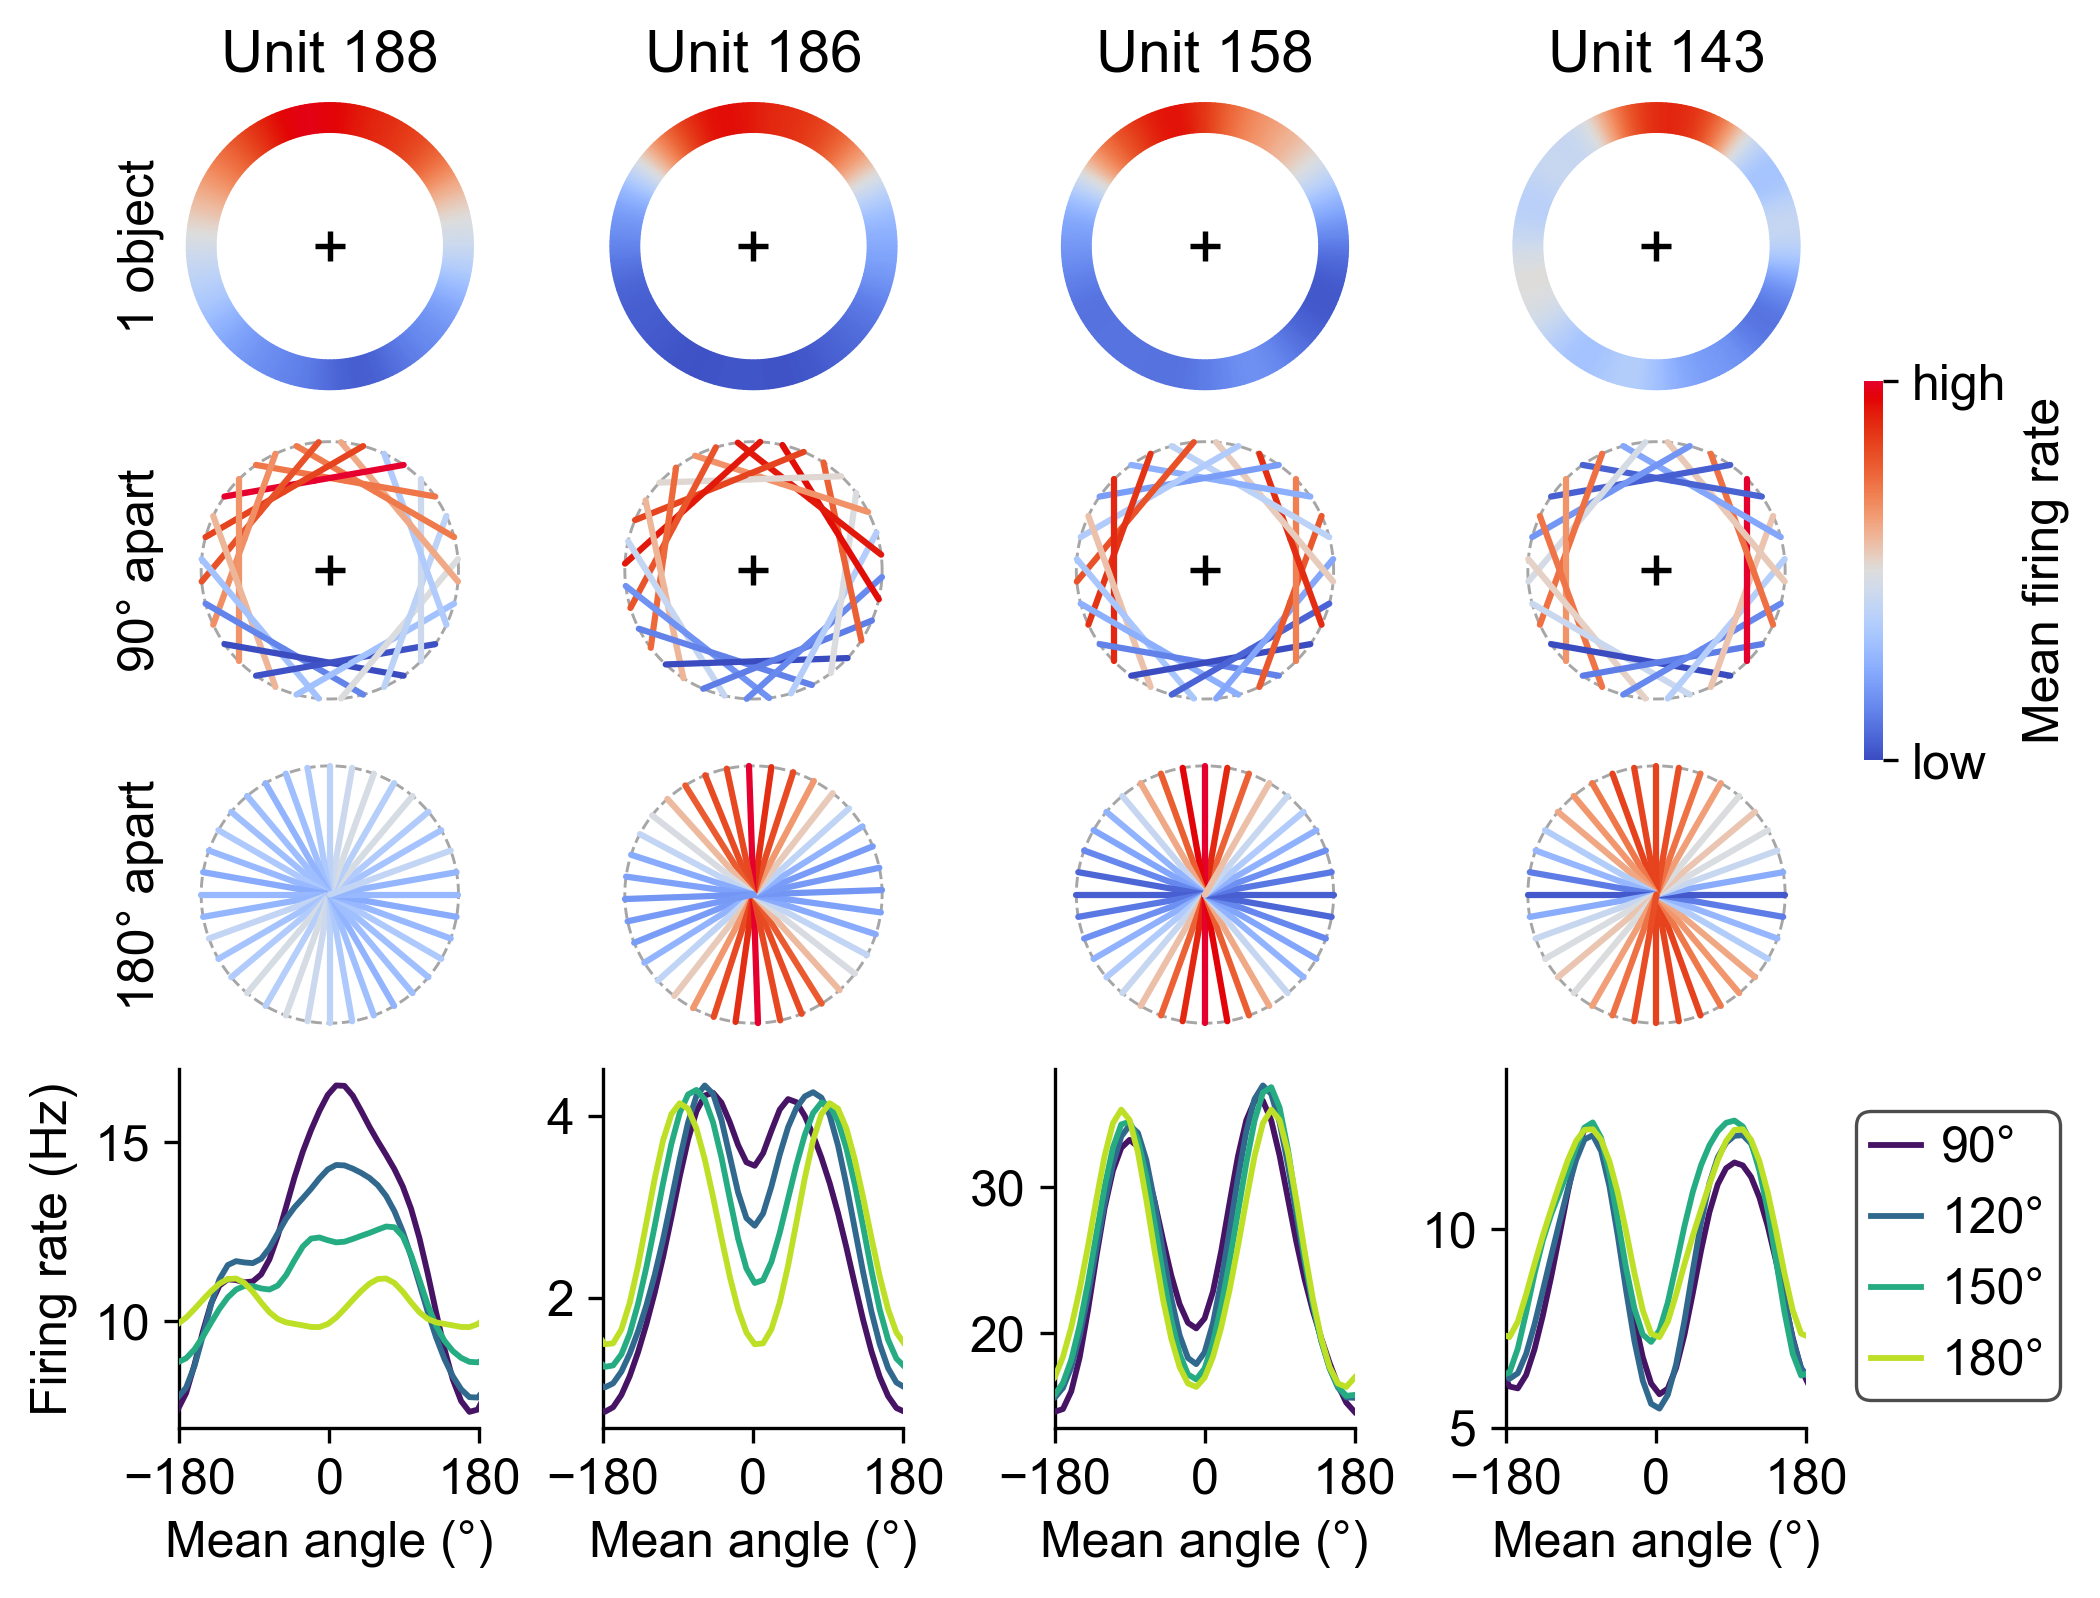

In [9]:
fig, axes = tuning_lib.tuning_grid(
    rows_per_unit,
    column_titles=[f'Unit {u}' for _, _, u, _ in UNITS],
    figsize=FIGSIZE, ring_size_in=RING_SIZE_IN,
    rotate_deg=[deg for _, _, _, deg in UNITS],
    curves_per_unit=curves_per_unit,
    line_colors=tuning_lib.sep_colors(LINE_SEPS_DEG),
    line_smooth_deg_2obj=LINE_SMOOTH_DEG_2OBJ,
    line_smooth_deg_1obj=LINE_SMOOTH_DEG_1OBJ,
    line_ylim=[LINE_YLIM.get(u) for _, _, u, _ in UNITS],
    line_yticks=[LINE_YTICKS.get(u) for _, _, u, _ in UNITS])
common.save(fig, 'tuning_plots.pdf')
plt.show()